# Dual-Branch (ResNet50 ‖ Swin-T) para classificação binária de mamografias: generalização entre datasets

Modelo **dual-branch**: a mesma imagem entra em paralelo por um ramo **CNN (ResNet50)** e um ramo **Transformer (Swin-T)**. Os vetores de características de cada ramo são concatenados e passam por uma camada densa que gera 1 logit para **Normal (0) vs Anormal (1 = benigno + maligno)**.

### Modificação:

Subamostragem por wavelet nos dois ramos.** As operações tradicionais de redução de resolução são trocadas por DWT 2D com **filtros treináveis** (inicializados nas wavelets clássicas):

- **Ramo CNN:** o `maxpool` do stem do ResNet50 vira `WaveletPool2d4Band` com **Daubechies 4 (db4) treinável**, 4 sub-bandas + conv 1×1 (base: notebook `06_cnn_..._db4`).
- **Ramo Swin:** o concat 2×2 do `PatchMerging` vira **Haar 2D treinável** (LL, LH, HL, HH), mantendo `norm` e `reduction` pré-treinados (base: notebook `03_swin_..._haar`).

Mesmos dados, protocolo, hiperparâmetros, augmentation e fine-tuning em duas fases dos notebooks isolados do ResNet50 e do Swin-T. A única mudança é o modelo, para que a comparação seja justa.

| Dataset | Imagens | Normais | Anormais |
|---|---|---|---|
| mini-MIAS | 318 | 207 (65,1 %) | 111 (34,9 %) |
| Mini-DDSM (Complete) | 3.716 | 2.408 (64,8 %) | 1.308 (35,2 %) |

**Protocolo**
1. **Exp. 1:** validação cruzada interna, 5-fold agrupada por paciente.
2. **Exp. 2:** treina em um dataset e testa no outro (nos dois sentidos, 3 sementes).
3. **Análise:** queda de AUC, IC 95 % por bootstrap de pacientes, ROC, matrizes de confusão e deslocamento de limiar.

> Limiar e early stopping nunca usam o teste. Saem de uma validação interna separada por paciente.

## 1. Setup

In [1]:
!pip install -q timm albumentations
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, hashlib, random, re, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm
import torchvision
from torchvision import models

import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
from scipy import ndimage as ndi
from joblib import Parallel, delayed

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             f1_score, precision_score, accuracy_score)

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")


def seed_everything(seed: int):
    # fixa todas as seeds
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {DEVICE}")

Mounted at /content/drive
device: cuda


## 2. Configuração

Parâmetros em `CONFIG`. `QUICK_TEST=True` faz um teste rápido (2 épocas, 1 semente, 100 bootstraps).

In [ ]:
CONFIG = dict(
    # caminhos
    OUTPUT_DIR = "/content/drive/MyDrive/TCC/outputs_dual_branch_clahe_roi",
    CACHE_DIR  = "./cache",
    NPZ_PATH   = "/content/drive/MyDrive/TCC/dados_preprocessados_roi.npz",

    # pré-processamento
    IMG_SIZE         = 224,

    # modelo (dual-branch: ResNet50 || Swin-T -> concat -> camada densa)
    MODEL_NAME  = "dual_resnet50_swin_tiny",
    CNN_NAME    = "resnet50",                  # torchvision.models.resnet50
    CNN_WEIGHTS = "IMAGENET1K_V1",             # ImageNet-1k, torchvision
    SWIN_NAME   = "swin_tiny_patch4_window7_224",   # timm
    PRETRAINED  = True,
    POOLING_CNN  = "db4_trainable",   # ResNet50: 'maxpool' | 'haar_ll' | 'haar4' | 'bior13' | 'coif1' | 'db4' (4 sub-bandas + conv 1x1) | 'db4_trainable' (idem, filtros db4 treináveis)
    POOLING_SWIN = "haar_trainable",  # Swin-T: 'patch_merging' (baseline) | 'haar' (Haar 2D fixa no lugar do concat 2x2) | 'haar_trainable' (idem, filtros Haar treináveis)
    NUM_CLASSES = 1,              # 1 logit + BCEWithLogitsLoss

    # fine-tuning em duas fases
    FREEZE_BACKBONE_EPOCHS = 5,  # épocas só com a cabeça
    HEAD_LR          = 3e-4,     # LR da cabeça
    BACKBONE_LR      = 1e-5,     # LR do backbone
    WAVELET_LR       = 1e-5,     # LR dos filtros wavelet treináveis (fase 2, sem weight decay)

    # treino
    BATCH_SIZE       = 32,
    EPOCHS           = 30,
    LEARNING_RATE    = 1e-4,
    WEIGHT_DECAY     = 0.05,
    USE_POS_WEIGHT   = True,
    USE_AMP          = True,      # só GPU
    GRAD_CLIP        = 1.0,
    EARLY_STOPPING   = True,
    PATIENCE         = 7,
    MIN_EPOCHS       = 5,
    ES_METRIC        = "val_auc", # 'val_auc' ou 'val_loss'
    THRESHOLD_METHOD = "youden",  # 'youden' ou 'f1'
    INNER_VAL_FRAC   = 0.15,      # fração do treino (por paciente) usada como validação

    # experimentos
    N_SPLITS  = 5,
    EXP1_SEED = 42,
    SEEDS     = [42, 123, 999],
    N_BOOT    = 1000,
    BOOT_SEED = 0,

    # sistema
    NUM_WORKERS = 0,              # 0 evita problemas no Windows
    N_JOBS      = -1,

    QUICK_TEST = False,
)

if CONFIG["QUICK_TEST"]:
    CONFIG.update(EPOCHS=2, PATIENCE=2, MIN_EPOCHS=1, SEEDS=CONFIG["SEEDS"][:1], N_BOOT=100)

assert CONFIG["NUM_CLASSES"] == 1, "Usa 1 logit (BCEWithLogitsLoss)."

assert CONFIG["POOLING_CNN"] in {"maxpool", "haar_ll", "haar4", "bior13", "coif1", "db4", "db4_trainable"}
assert CONFIG["POOLING_SWIN"] in {"patch_merging", "haar", "haar_trainable"}
POOL_TAG = f"{CONFIG['POOLING_CNN']}_{CONFIG['POOLING_SWIN']}"
CONFIG["OUTPUT_DIR"] += "_" + POOL_TAG                 # cada variante salva na própria pasta

OUT = Path(CONFIG["OUTPUT_DIR"])
OUT.mkdir(parents=True, exist_ok=True)
Path(CONFIG["CACHE_DIR"]).mkdir(parents=True, exist_ok=True)

## 3. Dados e pré-processamento

Mesmo pipeline nos dois datasets: segmenta a mama (Otsu), põe a parede torácica à esquerda, normaliza (min-max), faz padding para quadrado e redimensiona para 224×224. No modo `full` usa a mama inteira; no modo `roi`, uma janela quadrada de 30 % da altura da mama. Augmentation só no treino, sem flip horizontal.

- **Com coordenada da lesão (modo `roi`):** janela centrada nela. MIAS: centro da anomalia no `mias_info`. DDSM: centroide da máscara (`_Mask.jpg`), maior lesão.
- **Sem coordenada:** janela de mesmo tamanho, centro sorteado no tecido da mama (semente fixa). O tamanho do recorte não distingue as classes.

O dataset é gerado por `gerar_dataset_roi.py` (já com CLAHE) e carregado do `.npz`. As funções desta seção são as do script e só rodam na geração.

In [5]:
# ---- Dataset, augmentation e DataLoader ----
class MammoDataset(Dataset):
    # X: (N, H, W) uint8 já pré-processado; idx: índices deste subconjunto
    def __init__(self, X, y, idx, transform=None):
        self.X, self.y, self.idx, self.transform = X, y, np.asarray(idx), transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = np.repeat(self.X[j][..., None], 3, axis=-1)        # 1 canal -> 3
        if self.transform is not None:
            img = self.transform(image=img)["image"]
        return img, torch.tensor(self.y[j], dtype=torch.float32)


IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = A.Compose([
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])
eval_tf = A.Compose([
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD, max_pixel_value=255.0),
    ToTensorV2(),
])


def make_loader(X, y, idx, train, seed=0):
    g = torch.Generator().manual_seed(seed)
    ds = MammoDataset(X, y, idx, train_tf if train else eval_tf)
    return DataLoader(ds, batch_size=CONFIG["BATCH_SIZE"], shuffle=train, drop_last=False,
                      num_workers=CONFIG["NUM_WORKERS"], pin_memory=(DEVICE.type == "cuda"),
                      generator=g if train else None, persistent_workers=CONFIG["NUM_WORKERS"] > 0)

In [6]:
# carrega imagens 224x224, rótulos e id do paciente
assert Path(CONFIG["NPZ_PATH"]).exists(), "Gere o .npz com gerar_dataset_roi.py e suba para o Drive."
z = np.load(CONFIG["NPZ_PATH"], allow_pickle=True)
DATA = {n: dict(df=None, X=z[f"{n}_X"], y=z[f"{n}_y"], groups=z[f"{n}_g"].astype(str)) for n in ["mias", "ddsm"]}

print({n: (d["X"].shape, int(d["y"].sum())) for n, d in DATA.items()})

{'mias': ((318, 224, 224), 111), 'ddsm': ((3716, 224, 224), 1308)}


## 4. Modelo (dual-branch, subamostragem por wavelet treinável)

Os dois ramos usam os mesmos pesos ImageNet dos notebooks isolados, com a cabeça original removida (`fc = Identity` no ResNet50, `num_classes=0` no Swin-T). A única parte nova e inicializada do zero é a camada densa de fusão (`head`).

**Modificação 1, ramo CNN: `maxpool` → wavelet Daubechies 4 TREINÁVEL (`db4_trainable`, 4 sub-bandas).** O `maxpool` do stem (112×112 → 56×56) é trocado por `WaveletPool2d4Band`:
1. **DWT 2D com wavelet treinável (db4)**, 1 nível, por canal (`groups=C`). Os filtros 1D passa-baixa e passa-alta (`lo` e `hi`, 8 coeficientes cada, compartilhados por todos os canais) são `nn.Parameter` iniciados na db4; os filtros 2D (produtos externos, refeitos a cada forward) geram LL, LH, HL, HH → 4C canais com metade da resolução. Padding por reflexão (4 px à esquerda/topo e 2 px à direita/base) mantém 112 → 56 e alinha com `pywt.dwt`. Os filtros aprendem sem restrição de ortogonalidade, sem weight decay e com LR próprio (`WAVELET_LR`).
2. **Conv 1×1 treinável (4C → C)** devolve os 64 canais que a `layer1` pré-treinada espera. Inicia copiando só o LL (peso 1 no LL, 0 nas demais); LH/HL/HH só entram se reduzirem a loss.

**Modificação 2, ramo Swin: `PatchMerging` → wavelet Haar TREINÁVEL (`haar_trainable`).** O concat dos 4 vizinhos 2×2 é trocado por uma **Haar 2D de 1 nível com filtros treináveis** (LL, LH, HL, HH, C canais cada). Os filtros 1D `lo` e `hi` (2 coeficientes cada, por camada de merging) são `nn.Parameter` iniciados na Haar, com a mesma regra de LR e weight decay do ramo CNN. As 4 bandas são concatenadas em 4C canais (mesmo formato do concat original) e seguem para `norm` e `reduction` **pré-treinadas**.

As variantes de ablação ficam em `CONFIG["POOLING_CNN"]` (`db4` fixa ou `db4_trainable`) e `CONFIG["POOLING_SWIN"]` (`haar` fixa ou `haar_trainable`). Os filtros treináveis somam 16 parâmetros no ramo CNN e 12 no ramo Swin (3 camadas × 4). Com `maxpool` + `patch_merging` o modelo volta ao dual-branch original. Os strides das convoluções da `layer2`–`layer4` do ResNet50 não são alterados (igual ao notebook isolado db4).

**Fine-tuning em duas fases (igual aos modelos isolados):**
1. Treina só a camada densa (`head`) e a conv 1×1 da wavelet por `FREEZE_BACKBONE_EPOCHS` épocas, com o resto dos dois ramos congelado.
2. Descongela tudo: LR menor nos dois ramos (`BACKBONE_LR`), maior na camada densa e na conv 1×1 (`HEAD_LR`, a conv 1×1 sem weight decay). Os filtros wavelet ficam congelados na fase 1 e são liberados aqui, com `WAVELET_LR` e sem weight decay.

O modelo expõe `get_classifier()` apontando para `head`; a conv 1×1 é tratada à parte no código de treino.

In [7]:
import torch.nn.functional as F


# ---- Wavelets no ramo CNN (notebook 06, com opção de filtros treináveis) ----
class HaarPool2d(nn.Module):
    # DWT Haar 2D de 1 nível; devolve só a sub-banda LL (C canais). Sem parâmetros.
    def forward(self, x):
        H, W = x.shape[-2] // 2 * 2, x.shape[-1] // 2 * 2     # garante tamanho par
        x = x[..., :H, :W]
        a, b = x[..., 0::2, 0::2], x[..., 0::2, 1::2]
        c, d = x[..., 1::2, 0::2], x[..., 1::2, 1::2]
        return (a + b + c + d) * 0.5                           # LL ortonormal


# coeficientes de decomposição (mesmos de pywt.Wavelet(nome).dec_lo / dec_hi)
_WAVELETS = {
    "haar":   ([0.7071067811865476, 0.7071067811865476],
               [-0.7071067811865476, 0.7071067811865476]),
    "bior1.3": ([-0.08838834764831845, 0.08838834764831845, 0.7071067811865476,
                  0.7071067811865476, 0.08838834764831845, -0.08838834764831845],
                [0.0, 0.0, -0.7071067811865476, 0.7071067811865476, 0.0, 0.0]),
    "coif1":  ([-0.015655728135791993, -0.07273261951252645, 0.3848648468648578,
                 0.8525720202116004, 0.3378976624574818, -0.07273261951252645],
                [0.07273261951252645, 0.3378976624574818, -0.8525720202116004,
                 0.3848648468648578, 0.07273261951252645, -0.015655728135791993]),
    "db4":    ([-0.010597401785069032, 0.0328830116668852, 0.030841381835560764,
                 -0.18703481171909309, -0.027983769416859854, 0.6308807679298589,
                 0.7148465705529157, 0.2303778133088965],
                [-0.2303778133088965, 0.7148465705529157, -0.6308807679298589,
                 -0.027983769416859854, 0.18703481171909309, 0.030841381835560764,
                 -0.0328830116668852, -0.010597401785069032]),
}
POOLING_TO_WAVELET = {"haar4": "haar", "bior13": "bior1.3", "coif1": "coif1", "db4": "db4", "db4_trainable": "db4"}


class WaveletPool2d4Band(nn.Module):
    # DWT 2D de 1 nível (LL, LH, HL, HH) + conv 1x1 treinável 4C -> C, iniciada como "copia o LL".
    # trainable_wavelet=False: filtros lo/hi fixos (buffer). True: lo/hi viram nn.Parameter (iniciados na wavelet escolhida).
    def __init__(self, in_channels, wavelet="db4", trainable_wavelet=False):
        super().__init__()
        self.C = in_channels
        self.trainable_wavelet = trainable_wavelet
        lo, hi = _WAVELETS[wavelet]
        # F.conv2d faz correlação; a DWT usa convolução -> inverte os filtros
        lo = torch.tensor(lo[::-1], dtype=torch.float32)
        hi = torch.tensor(hi[::-1], dtype=torch.float32)
        k = lo.numel()
        # padding total k-2 (112 -> 56); assimétrico (esq/topo, dir/base) para alinhar com pywt.dwt: haar 0,0 | bior1.3 e coif1 2,2 | db4 4,2
        self.pad_l = max(k - 4, 0)
        self.pad_r = (k - 2) - self.pad_l
        if trainable_wavelet:
            self.lo = nn.Parameter(lo)             # filtros 1D treináveis (compartilhados entre os canais)
            self.hi = nn.Parameter(hi)
        else:
            self.register_buffer("lo", lo)         # buffer: fora do otimizador e do weight decay
            self.register_buffer("hi", hi)
        self.mix = nn.Conv2d(4 * in_channels, in_channels, kernel_size=1)
        with torch.no_grad():
            self.mix.weight.zero_()
            self.mix.bias.zero_()
            for c in range(in_channels):
                self.mix.weight[c, 4 * c, 0, 0] = 1.0   # saída c <- banda LL do canal c

    def _filters(self):
        # produtos externos dos filtros 1D -> (4C, 1, k, k); recalculado a cada forward para o gradiente chegar em lo/hi
        lo, hi = self.lo, self.hi
        f = torch.stack([torch.outer(lo, lo),      # LL
                         torch.outer(hi, lo),      # LH (passa-alta nas linhas)
                         torch.outer(lo, hi),      # HL (passa-alta nas colunas)
                         torch.outer(hi, hi)])     # HH           -> (4, k, k)
        return f.unsqueeze(1).repeat(self.C, 1, 1, 1)

    def forward(self, x):
        if self.pad_l + self.pad_r > 0:
            x = F.pad(x, (self.pad_l, self.pad_r, self.pad_l, self.pad_r), mode="reflect")
        x = F.conv2d(x, self._filters(), stride=2, groups=self.C)   # (N, 4C, H/2, W/2); ordem: c0_LL, c0_LH, c0_HL, c0_HH, c1_LL...
        return self.mix(x)


# ---- Wavelet no ramo Swin (notebook 03, com opção de filtros treináveis) ----
class HaarPatchMerging(nn.Module):
    # Troca o concat 2x2 do PatchMerging por uma Haar 2D de 1 nível (LL, LH, HL, HH).
    # trainable_wavelet=False: filtros lo/hi fixos (buffer). True: lo/hi viram nn.Parameter (iniciados na Haar).
    # norm e reduction pré-treinados são reaproveitados (transfer learning).
    def __init__(self, old, trainable_wavelet=False):
        super().__init__()
        self.trainable_wavelet = trainable_wavelet
        self.norm = old.norm
        self.reduction = old.reduction            # Linear 4C -> 2C
        s = 0.7071067811865476                    # 1/sqrt(2); mesmos de pywt.Wavelet('haar')
        # filtros de decomposição invertidos (o agrupamento 2x2 abaixo é uma correlação)
        lo = torch.tensor([s, s], dtype=torch.float32)
        hi = torch.tensor([s, -s], dtype=torch.float32)
        if trainable_wavelet:
            self.lo = nn.Parameter(lo)            # filtros 1D treináveis (compartilhados entre os canais)
            self.hi = nn.Parameter(hi)
        else:
            self.register_buffer("lo", lo)        # buffer: fora do otimizador e do weight decay
            self.register_buffer("hi", hi)

    def _filters(self):
        # produtos externos dos filtros 1D -> (4, 2, 2); recalculado a cada forward para o gradiente chegar em lo/hi
        lo, hi = self.lo, self.hi
        return torch.stack([torch.outer(lo, lo),      # LL
                            torch.outer(hi, lo),      # LH
                            torch.outer(lo, hi),      # HL
                            torch.outer(hi, hi)])     # HH

    def _bands(self, x):                          # x: (B, H, W, C) -> (B, H/2, W/2, 4C)
        H, W = x.shape[1] // 2 * 2, x.shape[2] // 2 * 2    # garante tamanho par
        x = x[:, :H, :W]
        a, b = x[:, 0::2, 0::2], x[:, 0::2, 1::2]
        c, d = x[:, 1::2, 0::2], x[:, 1::2, 1::2]
        f = self._filters()
        bands = [f[k, 0, 0] * a + f[k, 0, 1] * b + f[k, 1, 0] * c + f[k, 1, 1] * d for k in range(4)]
        return torch.cat(bands, dim=-1)           # ordem LL, LH, HL, HH; mesmo formato do concat original

    def forward(self, x):
        return self.reduction(self.norm(self._bands(x)))


class DualBranchNet(nn.Module):
    # ramo CNN (ResNet50, maxpool -> wavelet) e ramo Transformer (Swin-T, PatchMerging -> Haar) em paralelo;
    # features concatenadas -> camada densa
    def __init__(self):
        super().__init__()
        weights = getattr(models.ResNet50_Weights, CONFIG["CNN_WEIGHTS"]) if CONFIG["PRETRAINED"] else None
        self.cnn = models.resnet50(weights=weights)
        cnn_dim = self.cnn.fc.in_features                 # 2048
        self.cnn.fc = nn.Identity()                       # devolve o vetor após o avgpool

        # subamostragem do stem do ResNet50 conforme CONFIG["POOLING_CNN"]
        pc = CONFIG["POOLING_CNN"]
        if pc == "haar_ll":
            self.cnn.maxpool = HaarPool2d()
        elif pc in POOLING_TO_WAVELET:
            self.cnn.maxpool = WaveletPool2d4Band(self.cnn.conv1.out_channels, POOLING_TO_WAVELET[pc],
                                                  trainable_wavelet=pc.endswith("_trainable"))   # 64 canais

        self.swin = timm.create_model(
            CONFIG["SWIN_NAME"],
            pretrained=CONFIG["PRETRAINED"],
            num_classes=0,                                # sem cabeça: devolve o vetor pooled
            img_size=CONFIG["IMG_SIZE"],
        )
        swin_dim = self.swin.num_features                 # 768

        # PatchMerging do Swin conforme CONFIG["POOLING_SWIN"]
        if CONFIG["POOLING_SWIN"] in ("haar", "haar_trainable"):
            for layer in self.swin.layers:
                if type(layer.downsample).__name__ == "PatchMerging":
                    layer.downsample = HaarPatchMerging(layer.downsample,
                                                        trainable_wavelet=(CONFIG["POOLING_SWIN"] == "haar_trainable"))

        self.head = nn.Linear(cnn_dim + swin_dim, CONFIG["NUM_CLASSES"])   # camada densa de fusão

    def get_classifier(self):
        # mesma interface do timm, usada na separação cabeça/backbone
        return self.head

    def forward(self, x):
        f = torch.cat([self.cnn(x), self.swin(x)], dim=1)  # (B, 2048 + 768)
        return self.head(f)                                # (B, 1)


def build_model():
    return DualBranchNet()


# testes das camadas de pooling do ramo CNN
_x = torch.randn(2, 64, 112, 112)
assert torch.allclose(WaveletPool2d4Band(64, "haar")(_x), HaarPool2d()(_x), atol=1e-5)   # haar4 no início == só-LL
for _w in ("haar", "bior1.3", "coif1", "db4"):
    _p = WaveletPool2d4Band(64, _w)
    assert _p(_x).shape == (2, 64, 56, 56)
    _c = torch.full((1, 64, 112, 112), 3.0)                       # entrada constante: LL = 2*valor, detalhes = 0
    assert torch.allclose(_p(_c), torch.full((1, 64, 56, 56), 6.0), atol=1e-4)
# wavelet fixa: lo/hi são buffer, só a conv 1x1 é parâmetro
_p = WaveletPool2d4Band(64, "db4")
assert [n for n, _ in _p.named_buffers()] == ["lo", "hi"]
assert [n for n, _ in _p.named_parameters()] == ["mix.weight", "mix.bias"]
# wavelet treinável: lo/hi são parâmetros, sem buffers; no início, igual à fixa
_pt = WaveletPool2d4Band(64, "db4", trainable_wavelet=True)
assert [n for n, _ in _pt.named_buffers()] == []
assert [n for n, _ in _pt.named_parameters()] == ["lo", "hi", "mix.weight", "mix.bias"]
assert torch.allclose(_pt(_x), _p(_x), atol=1e-6)
_pt(_x).square().mean().backward()                            # o gradiente chega nos filtros
assert _pt.lo.grad is not None and _pt.lo.grad.abs().sum() > 0
assert _pt.hi.grad is not None                                # ~0 no início: a conv 1x1 ainda ignora as bandas de detalhe
del _x, _p, _pt, _c

# teste do ramo Swin: a Haar (fixa e treinável) reproduz as 4 bandas da fórmula original, e o gradiente chega em lo/hi
_old = nn.Module()
_old.norm, _old.reduction = nn.LayerNorm(4 * 96), nn.Linear(4 * 96, 2 * 96, bias=False)
_sf, _st = HaarPatchMerging(_old), HaarPatchMerging(_old, trainable_wavelet=True)
_x = torch.randn(2, 14, 14, 96)
_a, _b, _c, _d = _x[:, 0::2, 0::2], _x[:, 0::2, 1::2], _x[:, 1::2, 0::2], _x[:, 1::2, 1::2]
_ref = torch.cat([(_a + _b + _c + _d) * 0.5, (_a + _b - _c - _d) * 0.5,
                  (_a - _b + _c - _d) * 0.5, (_a - _b - _c + _d) * 0.5], dim=-1)
assert torch.allclose(_sf._bands(_x), _ref, atol=1e-5) and torch.allclose(_st._bands(_x), _ref, atol=1e-5)
assert [n for n, _ in _sf.named_parameters(recurse=False)] == [] and [n for n, _ in _sf.named_buffers(recurse=False)] == ["lo", "hi"]
assert [n for n, _ in _st.named_parameters(recurse=False)] == ["lo", "hi"] and [n for n, _ in _st.named_buffers(recurse=False)] == []
_st(_x).square().mean().backward()
assert _st.lo.grad.abs().sum() > 0 and _st.hi.grad.abs().sum() > 0   # reduction pré-treinada já usa as bandas de detalhe
del _old, _sf, _st, _x, _a, _b, _c, _d, _ref


# teste: parâmetros e saída
_m = build_model().eval()
n_params = sum(p.numel() for p in _m.parameters()) / 1e6
n_cnn = sum(p.numel() for p in _m.cnn.parameters()) / 1e6
n_swin = sum(p.numel() for p in _m.swin.parameters()) / 1e6
n_head = sum(p.numel() for p in _m.get_classifier().parameters())
n_haar = sum(isinstance(m, HaarPatchMerging) for m in _m.swin.modules())
n_wav = sum(isinstance(m, WaveletPool2d4Band) for m in _m.cnn.modules())
n_wavp = sum(p.numel() for n, p in _m.named_parameters() if n.split(".")[-1] in ("lo", "hi"))   # filtros wavelet treináveis (0 se fixos)
if CONFIG["POOLING_SWIN"] in ("haar", "haar_trainable"):
    assert n_haar == 3, n_haar                                  # 3 PatchMerging no Swin-T
if CONFIG["POOLING_CNN"] in POOLING_TO_WAVELET:
    assert n_wav == 1 and isinstance(_m.cnn.maxpool, WaveletPool2d4Band)
with torch.no_grad():
    out = _m(torch.zeros(2, 3, CONFIG["IMG_SIZE"], CONFIG["IMG_SIZE"]))
print(f"{CONFIG['MODEL_NAME']} | pooling CNN: {CONFIG['POOLING_CNN']} | pooling Swin: {CONFIG['POOLING_SWIN']} ({n_haar} camadas Haar) | "
      f"{n_wavp} parâmetros wavelet | "
      f"{n_params:.1f}M parâmetros (ResNet50 {n_cnn:.1f}M + Swin-T {n_swin:.1f}M) "
      f"| camada densa: {n_head} | saída: {tuple(out.shape)}")
del _m, out

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 49.5MB/s]


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

dual_resnet50_swin_tiny | pooling CNN: db4_trainable | pooling Swin: haar_trainable (3 camadas Haar) | 28 parâmetros wavelet | 51.0M parâmetros (ResNet50 23.5M + Swin-T 27.5M) | camada densa: 2817 | saída: (2, 1)


## 5. Treino e métricas

AdamW + cosine annealing (a conv 1×1 da wavelet entra no grupo da cabeça: `HEAD_LR`, sem weight decay; os filtros wavelet têm grupo próprio: `WAVELET_LR`, sem weight decay). `pos_weight` calculado só no treino. Early stopping na validação interna, restaurando os melhores pesos. Limiar por Youden (ou F1), também da validação interna.

Métrica principal: AUC. Secundárias: sensibilidade, especificidade, acurácia balanceada, F1 e precisão.

In [8]:
# ---- Métricas ----
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) > 1 else np.nan


def select_threshold(y, p, method=None):
    # usar só com validação
    method = method or CONFIG["THRESHOLD_METHOD"]
    if len(np.unique(y)) < 2:
        return 0.5
    if method == "youden":
        fpr, tpr, thr = roc_curve(y, p)
        j = tpr - fpr
        j[~np.isfinite(thr)] = -np.inf
        return float(thr[np.argmax(j)])
    if method == "f1":
        cands = np.unique(np.quantile(p, np.linspace(0.02, 0.98, 97)))
        scores = [f1_score(y, (p >= t).astype(int), zero_division=0) for t in cands]
        return float(cands[int(np.argmax(scores))])
    raise ValueError(method)


def compute_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan
    spec = tn / (tn + fp) if (tn + fp) else np.nan
    return dict(auc=safe_auc(y, p), sens=sens, spec=spec, bal_acc=np.nanmean([sens, spec]),
                f1=f1_score(y, pred, zero_division=0), precision=precision_score(y, pred, zero_division=0),
                acc=accuracy_score(y, pred), thr=thr)


METRIC_COLS = ["auc", "sens", "spec", "bal_acc", "f1", "precision"]


def mean_std_table(rows, cols=METRIC_COLS):
    df = pd.DataFrame(rows)
    return df[cols].agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)

In [9]:
# ---- Treino com transferência de aprendizado em duas fases ----
def _make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)


def _wavelet_mix(model):
    # conv 1x1 do WaveletPool2d4Band no ramo CNN (None se o maxpool não foi trocado por wavelet de 4 bandas)
    return getattr(getattr(getattr(model, "cnn", None), "maxpool", None), "mix", None)


def _wavelet_parameter_ids(model):
    # ids dos filtros wavelet treináveis (lo/hi) do ramo CNN e do ramo Swin; vazio se as wavelets forem fixas
    ids = set()
    for m in model.modules():
        if isinstance(m, (WaveletPool2d4Band, HaarPatchMerging)):
            ids |= {id(p) for p in m.parameters(recurse=False)}   # só lo/hi (mix, norm e reduction são submódulos)
    return ids


def _classifier_parameter_ids(model):
    # ids dos parâmetros da cabeça (via get_classifier; aqui, a camada densa de fusão) + conv 1x1 da wavelet
    if not hasattr(model, "get_classifier"):
        raise AttributeError("O modelo precisa de get_classifier().")
    classifier = model.get_classifier()
    if classifier is None:
        raise ValueError("Cabeça classificadora não encontrada.")
    ids = {id(p) for p in classifier.parameters()}
    mix = _wavelet_mix(model)                          # conv 1x1 da wavelet: treinável desde a fase 1
    if mix is not None:
        ids |= {id(p) for p in mix.parameters()}
    if not ids:
        raise ValueError("A cabeça não tem parâmetros treináveis.")
    return ids


def _set_trainable_phase(model, head_only):
    head_ids = _classifier_parameter_ids(model)
    for p in model.parameters():
        p.requires_grad = (id(p) in head_ids) if head_only else True
    return head_ids


@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    probs, losses, n = [], 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = model(xb).squeeze(1)
        logits = logits.float()
        if criterion is not None:
            losses += criterion(logits, yb).item() * len(yb)
            n += len(yb)
        probs.append(torch.sigmoid(logits).cpu().numpy())
    loss = losses / n if criterion is not None and n else np.nan
    return loss, np.concatenate(probs)


def predict_proba(model, X, y, idx):
    _, p = evaluate(model, make_loader(X, y, idx, train=False))
    return p


def _make_optimizer(model, head_ids, head_only):
    # backbones: BACKBONE_LR | camada densa: HEAD_LR | conv 1x1 da wavelet: HEAD_LR, sem weight decay | filtros wavelet: WAVELET_LR, sem weight decay
    mix = _wavelet_mix(model)
    mix_ids = {id(p) for p in mix.parameters()} if mix is not None else set()
    wav_ids = _wavelet_parameter_ids(model)
    head_params, backbone_params, mix_params, wav_params = [], [], [], []
    for p in model.parameters():
        if not p.requires_grad:
            continue
        if id(p) in wav_ids:
            wav_params.append(p)
        elif id(p) in mix_ids:
            mix_params.append(p)
        elif id(p) in head_ids:
            head_params.append(p)
        else:
            backbone_params.append(p)

    groups = []
    if backbone_params:
        groups.append({"params": backbone_params, "lr": CONFIG["BACKBONE_LR"]})
    if head_params:
        groups.append({"params": head_params, "lr": CONFIG["HEAD_LR"]})
    if mix_params:
        groups.append({"params": mix_params, "lr": CONFIG["HEAD_LR"], "weight_decay": 0.0})
    if wav_params:
        groups.append({"params": wav_params, "lr": CONFIG["WAVELET_LR"], "weight_decay": 0.0})
    return torch.optim.AdamW(groups, weight_decay=CONFIG["WEIGHT_DECAY"])


def train_model(X, y, tr_idx, va_idx, seed, mon_idx=None, verbose=True):
    # va_idx: validação interna (early stopping + limiar)
    # mon_idx: só monitoramento, não influencia o treino
    seed_everything(seed)
    model = build_model().to(DEVICE)
    head_ids = _set_trainable_phase(model, head_only=True)

    pw = 1.0
    if CONFIG["USE_POS_WEIGHT"]:
        pos = y[tr_idx].sum()
        neg = len(tr_idx) - pos
        pw = float(neg / max(pos, 1))
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pw], device=DEVICE))

    freeze_epochs = max(0, int(CONFIG["FREEZE_BACKBONE_EPOCHS"]))
    use_amp = CONFIG["USE_AMP"] and DEVICE.type == "cuda"
    scaler = _make_scaler(use_amp)

    tr_loader = make_loader(X, y, tr_idx, train=True, seed=seed)
    va_loader = make_loader(X, y, va_idx, train=False)
    mon_loader = make_loader(X, y, mon_idx, train=False) if mon_idx is not None else None

    # fase 1: otimizador da cabeça. Ao descongelar, cria um novo com LR por grupo.
    opt = _make_optimizer(model, head_ids, head_only=(freeze_epochs > 0))
    remaining = max(1, CONFIG["EPOCHS"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=remaining)

    hist = []
    best_score, best_state, best_epoch, bad = -np.inf, None, 0, 0
    for epoch in range(1, CONFIG["EPOCHS"] + 1):
        # libera o backbone na época freeze_epochs+1
        if freeze_epochs > 0 and epoch == freeze_epochs + 1:
            _set_trainable_phase(model, head_only=False)
            opt = _make_optimizer(model, head_ids, head_only=False)
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(
                opt, T_max=max(1, CONFIG["EPOCHS"] - freeze_epochs)
            )
            if verbose:
                print("  -> backbone descongelado; fine-tuning com LR discriminativa")

        model.train()
        if epoch <= freeze_epochs:
            # backbones em eval na fase congelada (evita atualizar BatchNorm do ResNet50); conv 1x1 da wavelet não tem BN
            model.eval()
            model.get_classifier().train()
        run, n = 0.0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = model(xb).squeeze(1)
            loss = criterion(logits.float(), yb)
            scaler.scale(loss).backward()
            if CONFIG["GRAD_CLIP"]:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad],
                    CONFIG["GRAD_CLIP"]
                )
            scaler.step(opt)
            scaler.update()
            run += loss.item() * len(yb)
            n += len(yb)
        sched.step()

        va_loss, va_p = evaluate(model, va_loader, criterion)
        va_auc = safe_auc(y[va_idx], va_p)
        rec = dict(epoch=epoch, train_loss=run / max(n, 1),
                   val_loss=va_loss, val_auc=va_auc,
                   phase=("head_only" if epoch <= freeze_epochs else "fine_tuning"))
        if mon_loader is not None:
            mon_loss, mon_p = evaluate(model, mon_loader, criterion)
            rec.update(mon_loss=mon_loss, mon_auc=safe_auc(y[mon_idx], mon_p))
        hist.append(rec)

        # early stopping: só validação interna
        if CONFIG["ES_METRIC"] == "val_auc" and not np.isnan(va_auc):
            score = va_auc
        else:
            score = -va_loss
        if score > best_score + 1e-4:
            best_score, bad, best_epoch = score, 0, epoch
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose:
            lrs = ",".join(f"{pg['lr']:.1e}" for pg in opt.param_groups)
            print(f"  ep {epoch:02d} | fase={rec['phase']} | LR={lrs} | "
                  f"train {rec['train_loss']:.4f} | val {va_loss:.4f} | "
                  f"val AUC {va_auc:.3f}" +
                  (f" | mon AUC {rec['mon_auc']:.3f}" if mon_loader is not None else ""))
        if (CONFIG["EARLY_STOPPING"] and epoch >= CONFIG["MIN_EPOCHS"]
                and bad >= CONFIG["PATIENCE"]):
            if verbose:
                print(f"  early stopping na época {epoch} (melhor: {best_epoch})")
            break

    if best_state is None:
        raise RuntimeError("Treino sem estado válido para restaurar.")
    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.attrs["best_epoch"] = best_epoch
    return model, hist


def group_holdout(y, groups, seed, frac):
    # separa por paciente, mantendo a proporção de classes
    n = max(2, int(round(1 / frac)))
    sgkf = StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=seed)
    tr, va = next(iter(sgkf.split(np.zeros(len(y)), y, groups)))
    return tr, va

## 6. Experimento 1: validação cruzada interna

5-fold com `StratifiedGroupKFold`. Nenhum paciente aparece em dois conjuntos (checado por `assert`). Em cada fold, o treino se divide por paciente em treino e validação interna (early stopping + limiar). O fold de teste só gera as métricas. Sua loss é plotada apenas para monitorar overfitting.

No Mini-DDSM demora. Use `QUICK_TEST=True` para testar antes.

[mias] fold 1/5 | treino=217 val=37 teste=64
  ep 01 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.9136 | val 0.9349 | val AUC 0.593 | mon AUC 0.686
  ep 02 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.9141 | val 0.9332 | val AUC 0.609 | mon AUC 0.717
  ep 03 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8964 | val 0.9191 | val AUC 0.593 | mon AUC 0.727
  ep 04 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8827 | val 0.9298 | val AUC 0.615 | mon AUC 0.730
  ep 05 | fase=head_only | LR=2.8e-04,2.8e-04 | train 0.8844 | val 0.9297 | val AUC 0.630 | mon AUC 0.742
  -> backbone descongelado; fine-tuning com LR discriminativa
  ep 06 | fase=fine_tuning | LR=1.0e-05,3.0e-04,3.0e-04,1.0e-05 | train 0.9566 | val 0.9867 | val AUC 0.596 | mon AUC 0.723
  ep 07 | fase=fine_tuning | LR=9.8e-06,3.0e-04,3.0e-04,9.8e-06 | train 0.8799 | val 0.9346 | val AUC 0.575 | mon AUC 0.758
  ep 08 | fase=fine_tuning | LR=9.6e-06,2.9e-04,2.9e-04,9.6e-06 | train 0.8510 | val 0.9585 | val AUC 0.693 | mon A

,valor
auc,0.789 ± 0.053
sens,0.753 ± 0.124
spec,0.656 ± 0.089
bal_acc,0.704 ± 0.059
f1,0.624 ± 0.065
precision,0.541 ± 0.067


Gap Val − Treino (loss, na melhor época): 0.224 ± 0.084


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,19,0.873,0.739,0.756,0.748,0.680,0.630,0.483,0.195
1,1,12,0.772,0.824,0.660,0.742,0.596,0.467,0.329,0.130
2,2,26,0.784,0.833,0.659,0.746,0.690,0.588,0.416,0.250
3,3,23,0.727,0.826,0.513,0.669,0.623,0.500,0.316,0.191
4,4,28,0.791,0.542,0.692,0.617,0.531,0.520,0.408,0.354



=== Experimento 1 — DDSM (média ± dp entre 5 folds) ===


,valor
auc,0.907 ± 0.009
sens,0.750 ± 0.027
spec,0.883 ± 0.033
bal_acc,0.817 ± 0.016
f1,0.763 ± 0.023
precision,0.779 ± 0.047


Gap Val − Treino (loss, na melhor época): 0.258 ± 0.110


,fold,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr,gap_val_minus_train
0,0,30,0.896,0.733,0.864,0.798,0.738,0.744,0.269,0.375
1,1,20,0.897,0.769,0.837,0.803,0.742,0.717,0.299,0.371
2,2,19,0.912,0.728,0.914,0.821,0.774,0.826,0.661,0.231
3,3,18,0.910,0.787,0.890,0.838,0.792,0.796,0.528,0.134
4,4,16,0.917,0.733,0.911,0.822,0.771,0.813,0.533,0.179


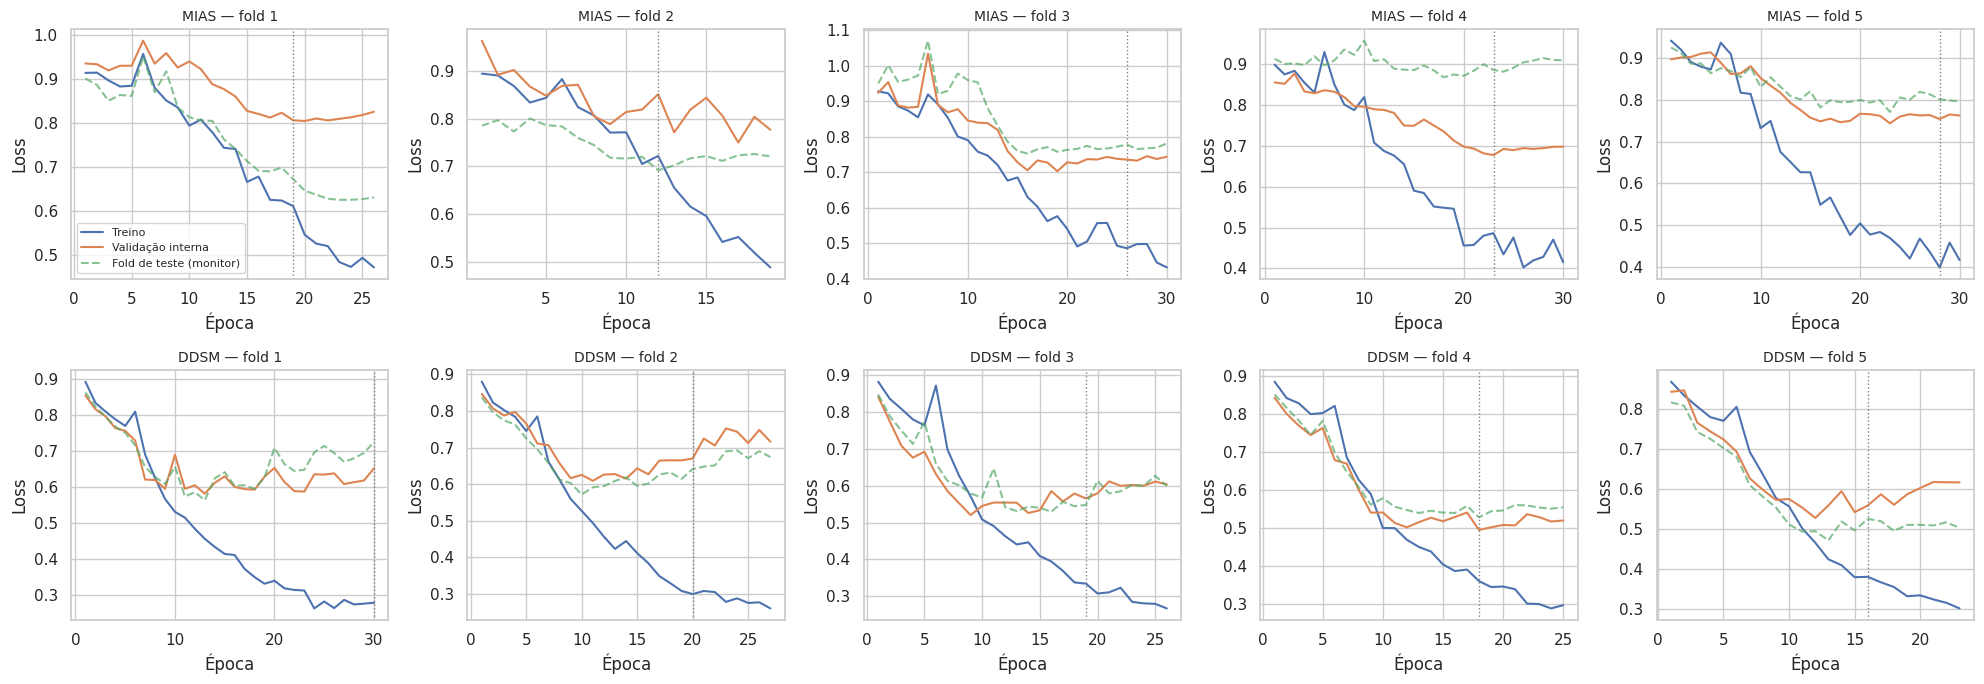

In [10]:
def run_experiment1(name, seed):
    d = DATA[name]
    X, y, g = d["X"], d["y"], d["groups"]
    outer = StratifiedGroupKFold(n_splits=CONFIG["N_SPLITS"], shuffle=True, random_state=seed)
    res = dict(folds=[], hist=[], oof=[])

    for fold, (tr_all, te) in enumerate(outer.split(X, y, g)):
        tr_in, va_in = group_holdout(y[tr_all], g[tr_all], seed + fold, CONFIG["INNER_VAL_FRAC"])
        tr, va = tr_all[tr_in], tr_all[va_in]
        # paciente em um só conjunto
        assert set(g[tr]).isdisjoint(g[va]) and set(g[tr]).isdisjoint(g[te]) and set(g[va]).isdisjoint(g[te])

        print(f"[{name}] fold {fold + 1}/{CONFIG['N_SPLITS']} | treino={len(tr)} val={len(va)} teste={len(te)}")
        model, hist = train_model(X, y, tr, va, seed + fold, mon_idx=te)

        p_va = predict_proba(model, X, y, va)
        thr = select_threshold(y[va], p_va)                  # limiar: validação interna
        p_te = predict_proba(model, X, y, te)
        m = compute_metrics(y[te], p_te, thr)

        b = hist.attrs["best_epoch"]
        row = hist[hist.epoch == b].iloc[0]
        m.update(dataset=name, fold=fold, best_epoch=b, gap_val_minus_train=row.val_loss - row.train_loss)
        res["folds"].append(m)
        res["hist"].append(hist)
        res["oof"].append(pd.DataFrame(dict(idx=te, y=y[te], p=p_te, pred=(p_te >= thr).astype(int),
                                            g=g[te], fold=fold)))
        print(f"  -> AUC={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    res["oof"] = pd.concat(res["oof"], ignore_index=True)
    return res


R1 = {}
for name in ["mias", "ddsm"]:
    R1[name] = run_experiment1(name, CONFIG["EXP1_SEED"])

with open(f"/content/drive/MyDrive/TCC/R1_dual_branch_{POOL_TAG}_clahe.pkl", "wb") as fh:
    pickle.dump(R1, fh)

# ---- Resumo: média ± dp entre folds ----
for name in ["mias", "ddsm"]:
    folds = pd.DataFrame(R1[name]["folds"])
    print(f"\n=== Experimento 1 — {name.upper()} (média ± dp entre {CONFIG['N_SPLITS']} folds) ===")
    display(mean_std_table(R1[name]["folds"]).to_frame("valor"))
    print(f"Gap Val − Treino (loss, na melhor época): "
          f"{folds.gap_val_minus_train.mean():.3f} ± {folds.gap_val_minus_train.std():.3f}")
    display(folds[["fold", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr",
                   "gap_val_minus_train"]].round(3))
    folds.to_csv(OUT / f"exp1_folds_{name}.csv", index=False)

# ---- Curvas de loss ----
fig, axes = plt.subplots(2, CONFIG["N_SPLITS"], figsize=(4 * CONFIG["N_SPLITS"], 7), squeeze=False)
for r, name in enumerate(["mias", "ddsm"]):
    for f, h in enumerate(R1[name]["hist"]):
        ax = axes[r, f]
        ax.plot(h.epoch, h.train_loss, label="Treino")
        ax.plot(h.epoch, h.val_loss, label="Validação interna")
        ax.plot(h.epoch, h.mon_loss, "--", alpha=0.7, label="Fold de teste (monitor)")
        ax.axvline(h.attrs["best_epoch"], color="gray", ls=":", lw=1)
        ax.set_title(f"{name.upper()} — fold {f + 1}", fontsize=10)
        ax.set_xlabel("Época")
        ax.set_ylabel("Loss")
        if r == 0 and f == 0:
            ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "exp1_loss_curves.png", dpi=150)
plt.show()

## 7. Experimento 2: domain shift direto

Treina em um dataset e avalia no outro inteiro, nos dois sentidos (mias → ddsm e ddsm → mias). Para cada semente, a origem é dividida por paciente em treino e validação interna. O limiar vem só da origem. Nada do destino entra no treino, na escolha da época ou no limiar.

In [11]:
def run_experiment2(src, tgt):
    Xs, ys, gs = DATA[src]["X"], DATA[src]["y"], DATA[src]["groups"]
    Xt, yt = DATA[tgt]["X"], DATA[tgt]["y"]
    out = dict(probs={}, thr={}, metrics=[], src_val=[])

    for s in CONFIG["SEEDS"]:
        tr, va = group_holdout(ys, gs, s, CONFIG["INNER_VAL_FRAC"])
        assert set(gs[tr]).isdisjoint(gs[va])
        print(f"[{src} -> {tgt}] seed {s} | treino={len(tr)} val={len(va)} | alvo={len(yt)}")
        model, hist = train_model(Xs, ys, tr, va, s, mon_idx=None)

        p_va = predict_proba(model, Xs, ys, va)
        thr = select_threshold(ys[va], p_va)                          # limiar: origem
        p_t = predict_proba(model, Xt, yt, np.arange(len(yt)))        # alvo inteiro
        m = compute_metrics(yt, p_t, thr)
        m.update(seed=s, direction=f"{src}->{tgt}", best_epoch=hist.attrs["best_epoch"])
        out["metrics"].append(m)
        out["src_val"].append(compute_metrics(ys[va], p_va, thr))
        out["probs"][s], out["thr"][s] = p_t, thr
        print(f"  -> AUC alvo={m['auc']:.3f} sens={m['sens']:.3f} spec={m['spec']:.3f} thr(origem)={thr:.3f}")
        del model
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    return out


R2 = {}
for src, tgt in [("mias", "ddsm"), ("ddsm", "mias")]:
    R2[(src, tgt)] = run_experiment2(src, tgt)

with open(f"/content/drive/MyDrive/TCC/R2_dual_branch_{POOL_TAG}_clahe.pkl", "wb") as fh:
    pickle.dump(R2, fh)

for (src, tgt), r in R2.items():
    print(f"\n=== Experimento 2 — {src.upper()} → {tgt.upper()} ({len(CONFIG['SEEDS'])} sementes) ===")
    df = pd.DataFrame(r["metrics"])
    display(df[["seed", "best_epoch", "auc", "sens", "spec", "bal_acc", "f1", "precision", "thr"]].round(3))
    display(mean_std_table(r["metrics"]).to_frame("média ± dp"))
    df.to_csv(OUT / f"exp2_{src}_to_{tgt}.csv", index=False)

[mias -> ddsm] seed 42 | treino=273 val=45 | alvo=3716
  ep 01 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.9286 | val 0.9022 | val AUC 0.622
  ep 02 | fase=head_only | LR=3.0e-04,3.0e-04 | train 0.8953 | val 0.8847 | val AUC 0.683
  ep 03 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8583 | val 0.8754 | val AUC 0.710
  ep 04 | fase=head_only | LR=2.9e-04,2.9e-04 | train 0.8837 | val 0.8812 | val AUC 0.670
  ep 05 | fase=head_only | LR=2.8e-04,2.8e-04 | train 0.8778 | val 0.9003 | val AUC 0.727
  -> backbone descongelado; fine-tuning com LR discriminativa
  ep 06 | fase=fine_tuning | LR=1.0e-05,3.0e-04,3.0e-04,1.0e-05 | train 0.9202 | val 0.8441 | val AUC 0.767
  ep 07 | fase=fine_tuning | LR=9.8e-06,3.0e-04,3.0e-04,9.8e-06 | train 0.8664 | val 0.8946 | val AUC 0.670
  ep 08 | fase=fine_tuning | LR=9.6e-06,2.9e-04,2.9e-04,9.6e-06 | train 0.8309 | val 0.8691 | val AUC 0.716
  ep 09 | fase=fine_tuning | LR=9.4e-06,2.8e-04,2.8e-04,9.4e-06 | train 0.8181 | val 0.8454 | val AUC 0.807
 

,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,16,0.646,0.306,0.872,0.589,0.397,0.565,0.582
1,123,29,0.627,0.456,0.744,0.600,0.473,0.492,0.278
2,999,25,0.643,0.428,0.785,0.607,0.470,0.520,0.379


,média ± dp
auc,0.639 ± 0.010
sens,0.397 ± 0.080
spec,0.800 ± 0.065
bal_acc,0.599 ± 0.009
f1,0.447 ± 0.043
precision,0.526 ± 0.037



=== Experimento 2 — DDSM → MIAS (3 sementes) ===


,seed,best_epoch,auc,sens,spec,bal_acc,f1,precision,thr
0,42,15,0.779,0.477,0.879,0.678,0.561,0.679,0.527
1,123,14,0.793,0.613,0.860,0.736,0.654,0.701,0.383
2,999,15,0.821,0.622,0.860,0.741,0.660,0.704,0.406


,média ± dp
auc,0.798 ± 0.021
sens,0.571 ± 0.081
spec,0.866 ± 0.011
bal_acc,0.718 ± 0.035
f1,0.625 ± 0.056
precision,0.695 ± 0.013


## 8. Análise

- **Drop** = AUC interno (Exp. 1) − AUC cruzado (Exp. 2).
- **IC 95 %:** bootstrap que reamostra pacientes, não imagens.
- **Predição cruzada agregada:** média das probabilidades entre sementes e média dos limiares de origem.
- **Limiar "oráculo":** usa rótulos do alvo. Só diagnóstico, não reportar como desempenho.

In [12]:
# ---- Bootstrap por paciente ----
def patient_bootstrap(y, p, groups, n_boot, seed):
    rng = np.random.RandomState(seed)
    ug, inv = np.unique(groups, return_inverse=True)
    by_g = [np.where(inv == i)[0] for i in range(len(ug))]
    vals = []
    for _ in range(n_boot):
        pick = rng.randint(0, len(ug), len(ug))
        idx = np.concatenate([by_g[i] for i in pick])
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    return np.array(vals)


def ci95(v):
    return np.percentile(v, [2.5, 97.5])


# ---- Predições internas (OOF) e cruzadas (ensemble) ----
OOF = {n: R1[n]["oof"] for n in ["mias", "ddsm"]}
CROSS = {}
for (src, tgt), r in R2.items():
    p_ens = np.mean([r["probs"][s] for s in CONFIG["SEEDS"]], axis=0)
    thr_ens = float(np.mean([r["thr"][s] for s in CONFIG["SEEDS"]]))
    CROSS[(src, tgt)] = dict(p=p_ens, thr=thr_ens, y=DATA[tgt]["y"], g=DATA[tgt]["groups"])

# ---- Tabela de generalização ----
rows = []
for (src, tgt) in R2:
    folds = pd.DataFrame(R1[src]["folds"])
    auc_int_fold = folds.auc.mean()
    o = OOF[src]
    auc_int_pool = roc_auc_score(o.y, o.p)
    b_int = patient_bootstrap(o.y.values, o.p.values, o.g.values, CONFIG["N_BOOT"], CONFIG["BOOT_SEED"])

    c = CROSS[(src, tgt)]
    seed_aucs = np.array([m["auc"] for m in R2[(src, tgt)]["metrics"]])
    auc_cross_ens = roc_auc_score(c["y"], c["p"])
    b_cr = patient_bootstrap(c["y"], c["p"], c["g"], CONFIG["N_BOOT"], CONFIG["BOOT_SEED"] + 1)

    m = min(len(b_int), len(b_cr))
    b_drop = b_int[:m] - b_cr[:m]
    drop_seed = auc_int_fold - seed_aucs
    lo_i, hi_i = ci95(b_int)
    lo_c, hi_c = ci95(b_cr)
    lo_d, hi_d = ci95(b_drop)
    rows.append({
        "Sentido": f"{src.upper()} → {tgt.upper()}",
        "AUC interno (média folds ± dp)": f"{auc_int_fold:.3f} ± {folds.auc.std():.3f}",
        "AUC interno OOF [IC95%]": f"{auc_int_pool:.3f} [{lo_i:.3f}, {hi_i:.3f}]",
        "AUC cruzado (sementes ± dp)": f"{seed_aucs.mean():.3f} ± {seed_aucs.std(ddof=1) if len(seed_aucs) > 1 else 0:.3f}",
        "AUC cruzado ensemble [IC95%]": f"{auc_cross_ens:.3f} [{lo_c:.3f}, {hi_c:.3f}]",
        "Drop (média folds − sementes ± dp)": f"{drop_seed.mean():.3f} ± {drop_seed.std(ddof=1) if len(drop_seed) > 1 else 0:.3f}",
        "Drop (OOF − ensemble) [IC95%]": f"{auc_int_pool - auc_cross_ens:.3f} [{lo_d:.3f}, {hi_d:.3f}]",
    })
gen_table = pd.DataFrame(rows).set_index("Sentido")
display(gen_table.T)
gen_table.to_csv(OUT / "generalization_summary.csv")

Sentido,MIAS → DDSM,DDSM → MIAS
AUC interno (média folds ± dp),0.789 ± 0.053,0.907 ± 0.009
AUC interno OOF [IC95%],"0.776 [0.723, 0.827]","0.904 [0.892, 0.915]"
AUC cruzado (sementes ± dp),0.639 ± 0.010,0.798 ± 0.021
AUC cruzado ensemble [IC95%],"0.649 [0.626, 0.670]","0.822 [0.772, 0.869]"
Drop (média folds − sementes ± dp),0.151 ± 0.010,0.109 ± 0.021
Drop (OOF − ensemble) [IC95%],"0.127 [0.071, 0.183]","0.082 [0.034, 0.133]"


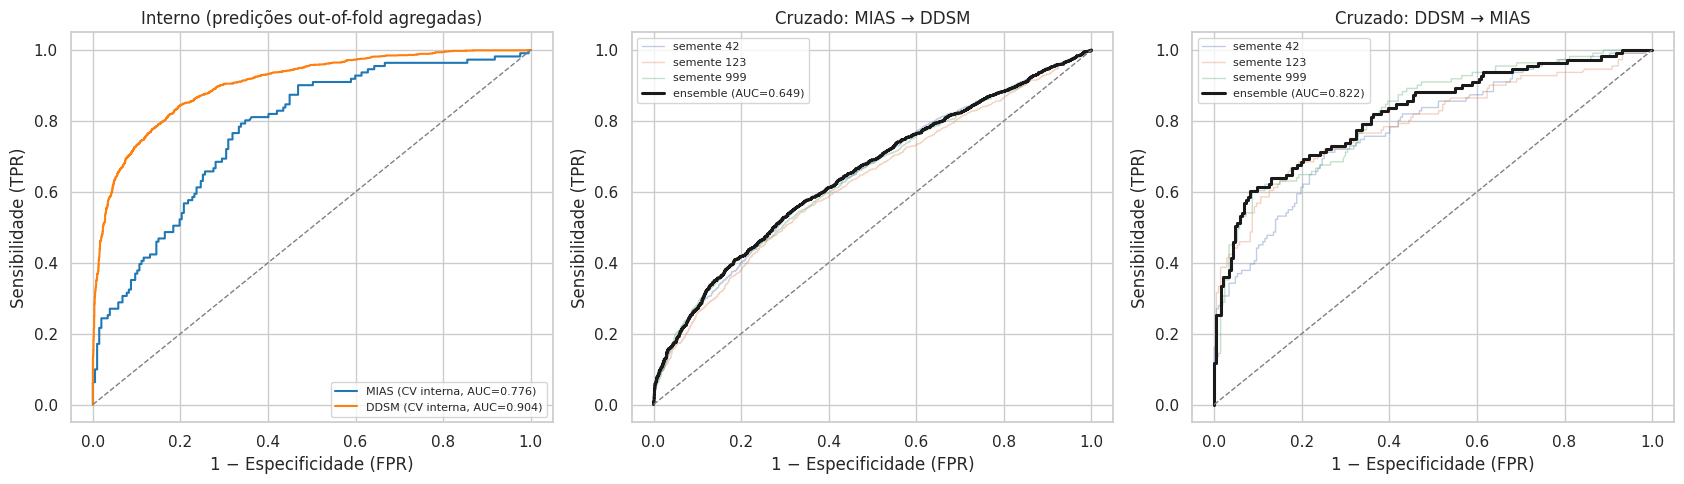

In [13]:
# ---- Curvas ROC ----
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
for n, col in [("mias", "tab:blue"), ("ddsm", "tab:orange")]:
    o = OOF[n]
    fpr, tpr, _ = roc_curve(o.y, o.p)
    ax.plot(fpr, tpr, color=col, label=f"{n.upper()} (CV interna, AUC={roc_auc_score(o.y, o.p):.3f})")
ax.set_title("Interno (predições out-of-fold agregadas)")

for ax, (src, tgt) in zip(axes[1:], R2):
    c = CROSS[(src, tgt)]
    for s in CONFIG["SEEDS"]:
        fpr, tpr, _ = roc_curve(c["y"], R2[(src, tgt)]["probs"][s])
        ax.plot(fpr, tpr, alpha=0.35, lw=1, label=f"semente {s}")
    fpr, tpr, _ = roc_curve(c["y"], c["p"])
    ax.plot(fpr, tpr, "k", lw=2.2, label=f"ensemble (AUC={roc_auc_score(c['y'], c['p']):.3f})")
    ax.set_title(f"Cruzado: {src.upper()} → {tgt.upper()}")

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
    ax.set_xlabel("1 − Especificidade (FPR)")
    ax.set_ylabel("Sensibilidade (TPR)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "roc_curves.png", dpi=150)
plt.show()

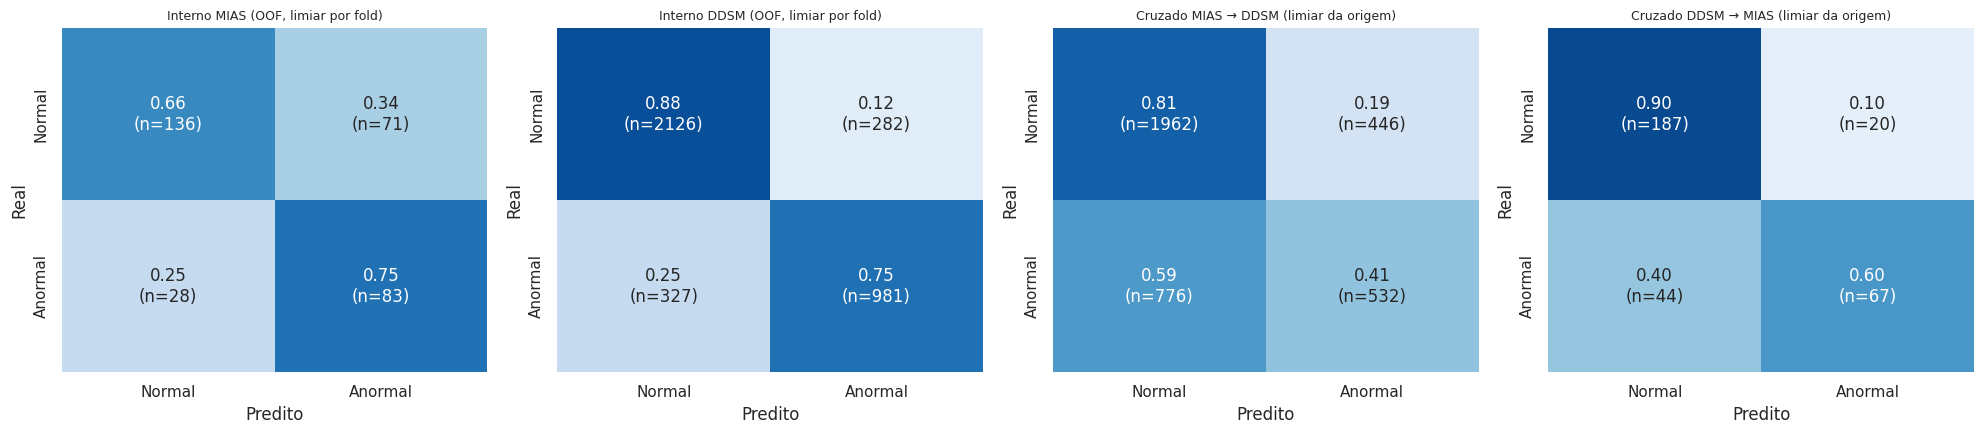

In [14]:
# ---- Matrizes de confusão ----
panels = [(f"Interno {n.upper()} (OOF, limiar por fold)", OOF[n].y.values, OOF[n].pred.values) for n in OOF]
panels += [(f"Cruzado {s.upper()} → {t.upper()} (limiar da origem)", CROSS[(s, t)]["y"],
            (CROSS[(s, t)]["p"] >= CROSS[(s, t)]["thr"]).astype(int)) for (s, t) in R2]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (title, yt_, yp_) in zip(axes, panels):
    cm = confusion_matrix(yt_, yp_, labels=[0, 1])
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cmn[i, j]:.2f}\n(n={cm[i, j]})" for j in range(2)] for i in range(2)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=["Normal", "Anormal"], yticklabels=["Normal", "Anormal"])
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrices.png", dpi=150)
plt.show()

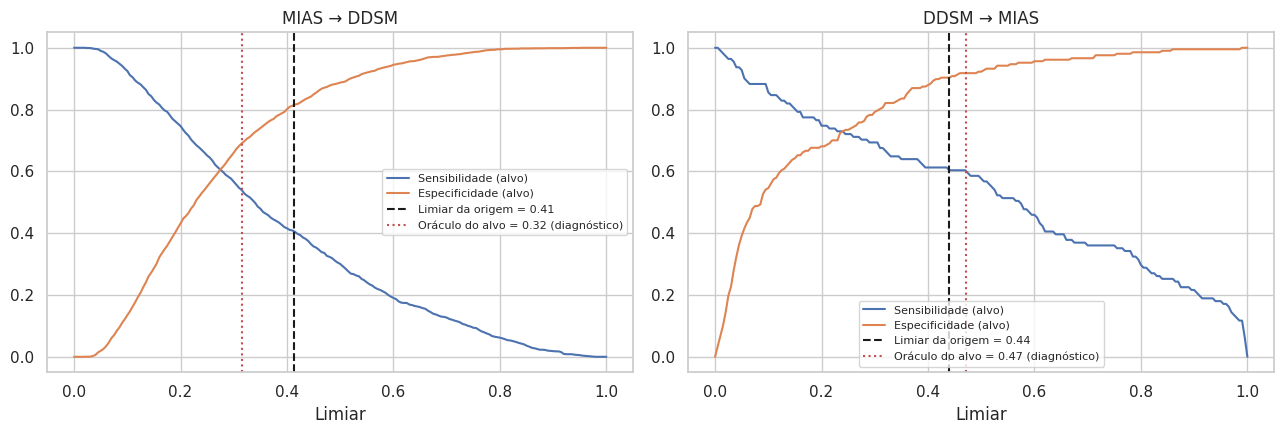

Sentido,MIAS → DDSM,DDSM → MIAS
Sens interna (origem),0.753,0.750
Esp interna (origem),0.656,0.883
Sens alvo @limiar origem,0.407,0.604
Esp alvo @limiar origem,0.815,0.903
Sens alvo @oráculo (diag.),0.540,0.604
Esp alvo @oráculo (diag.),0.691,0.918
Δ Sens (alvo − interna),-0.346,-0.146
Δ Esp (alvo − interna),0.159,0.020



Arquivos salvos em: /content/drive/MyDrive/TCC/outputs_dual_branch_clahe_roi_db4_trainable_haar_trainable


In [15]:
# ---- Deslocamento de limiar ----
ths = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
shift_rows = []
for ax, (src, tgt) in zip(axes, R2):
    c = CROSS[(src, tgt)]
    sens = [((c["p"] >= t) & (c["y"] == 1)).sum() / (c["y"] == 1).sum() for t in ths]
    spec = [((c["p"] < t) & (c["y"] == 0)).sum() / (c["y"] == 0).sum() for t in ths]
    ax.plot(ths, sens, label="Sensibilidade (alvo)")
    ax.plot(ths, spec, label="Especificidade (alvo)")
    ax.axvline(c["thr"], color="k", ls="--", label=f"Limiar da origem = {c['thr']:.2f}")
    t_or = select_threshold(c["y"], c["p"], "youden")   # só diagnóstico
    ax.axvline(t_or, color="r", ls=":", label=f"Oráculo do alvo = {t_or:.2f} (diagnóstico)")
    ax.set_title(f"{src.upper()} → {tgt.upper()}")
    ax.set_xlabel("Limiar")
    ax.legend(fontsize=8)

    internal = pd.DataFrame(R1[src]["folds"])
    mo = compute_metrics(c["y"], c["p"], c["thr"])
    mc = compute_metrics(c["y"], c["p"], t_or)
    shift_rows.append({"Sentido": f"{src.upper()} → {tgt.upper()}",
                       "Sens interna (origem)": internal.sens.mean(), "Esp interna (origem)": internal.spec.mean(),
                       "Sens alvo @limiar origem": mo["sens"], "Esp alvo @limiar origem": mo["spec"],
                       "Sens alvo @oráculo (diag.)": mc["sens"], "Esp alvo @oráculo (diag.)": mc["spec"]})
plt.tight_layout()
plt.savefig(OUT / "threshold_shift.png", dpi=150)
plt.show()

shift = pd.DataFrame(shift_rows).set_index("Sentido").round(3)
shift["Δ Sens (alvo − interna)"] = shift["Sens alvo @limiar origem"] - shift["Sens interna (origem)"]
shift["Δ Esp (alvo − interna)"] = shift["Esp alvo @limiar origem"] - shift["Esp interna (origem)"]
display(shift.T.round(3))
shift.to_csv(OUT / "threshold_shift.csv")
print(f"\nArquivos salvos em: {OUT.resolve()}")

## 9. Resumo das métricas

| Métrica | O que mede | Quando usar |
|---|---|---|
| **Acurácia** | Proporção de acertos gerais | Dados balanceados |
| **Precisão** | Confiabilidade das predições positivas | Evitar falsos positivos |
| **Recall** (sensibilidade) | Capacidade de encontrar positivos reais | Evitar falsos negativos |
| **F1-score** | Equilíbrio entre precisão e recall | Dados desbalanceados |
| **AUC-ROC** | Capacidade de separar as classes | Avaliação global do modelo |


In [16]:
# média ± dp entre folds (Exp. 1) ou sementes (Exp. 2)
COLS = {"acc": "Acurácia", "precision": "Precisão", "sens": "Recall", "f1": "F1-score", "auc": "AUC-ROC"}


def fmt(rows):
    df = pd.DataFrame(rows)[list(COLS)]
    return {v: f"{df[k].mean():.3f} ± {df[k].std():.3f}" for k, v in COLS.items()}


summary = {f"Exp. 1 — {n.upper()} (CV)": fmt(R1[n]["folds"]) for n in ["mias", "ddsm"]}
summary.update({f"Exp. 2 — {s.upper()} → {t.upper()}": fmt(r["metrics"]) for (s, t), r in R2.items()})
summary = pd.DataFrame(summary).T
display(summary)
summary.to_csv(OUT / "final_summary.csv")

,Acurácia,Precisão,Recall,F1-score,AUC-ROC
Exp. 1 — MIAS (CV),0.688 ± 0.054,0.541 ± 0.067,0.753 ± 0.124,0.624 ± 0.065,0.789 ± 0.053
Exp. 1 — DDSM (CV),0.836 ± 0.019,0.779 ± 0.047,0.750 ± 0.027,0.763 ± 0.023,0.907 ± 0.009
Exp. 2 — MIAS → DDSM,0.658 ± 0.015,0.526 ± 0.037,0.397 ± 0.080,0.447 ± 0.043,0.639 ± 0.010
Exp. 2 — DDSM → MIAS,0.763 ± 0.021,0.695 ± 0.013,0.571 ± 0.081,0.625 ± 0.056,0.798 ± 0.021
